Customer-Genre Matrix C (6x5):
 [[2.5 4.8 3.9 3.4 1.6]
 [1.6 1.2 4.5 3.4 3.8]
 [1.1 4.9 4.3 1.8 1.7]
 [1.7 2.2 3.1 2.7 2.2]
 [3.4 1.6 2.2 2.5 2.8]
 [4.1 1.8 3.1 3.4 1.2]]

Genre-Book Matrix G (5x4):
 [[0.61 0.17 0.07 0.95]
 [0.97 0.81 0.3  0.1 ]
 [0.68 0.44 0.12 0.5 ]
 [0.03 0.91 0.26 0.66]
 [0.31 0.52 0.55 0.18]]

Dot product (Cust_1 · Cust_2): 44.950
Customer-Book Score Matrix (6x4):
 [[9.431 9.955 3.847 7.337]
 [6.48  8.294 3.986 6.818]
 [8.929 8.57  3.466 5.179]
 [6.042 7.036 3.063 5.563]
 [6.065 6.573 3.172 6.644]
 [6.829 7.237 2.743 8.085]]

Determinant of 5x5 submatrix: -8.3706
Inverse valid? True
Check A @ A_inv ≈ I:
 [[ 1. -0.  0.  0. -0.]
 [-0.  1.  0.  0. -0.]
 [-0. -0.  1.  0.  0.]
 [-0. -0. -0.  1.  0.]
 [ 0.  0. -0.  0.  1.]]

Element-wise product (first 4x4):
 [[3.05 1.63 0.55 6.46]
 [3.1  1.94 2.7  0.68]
 [1.5  4.31 1.03 1.8 ]
 [0.1  4.   1.61 3.56]]

Most similar customers: Cust_1 & Cust_3 (similarity = 0.9598)

Dense layer manual y = Wx + b for Cust_1: [9.631 9.855 4.

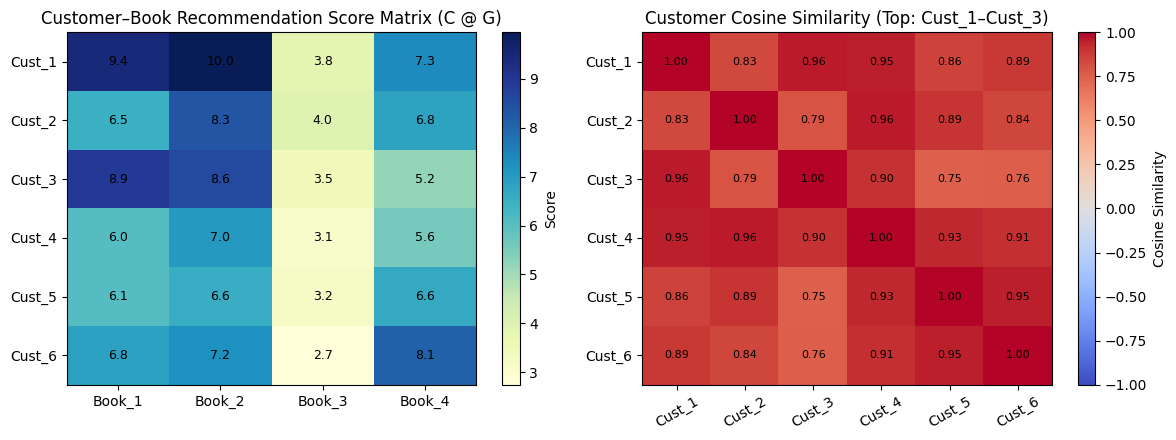

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

customers = [f"Cust_{i+1}" for i in range(6)]
genres = ["Sci-Fi", "Mystery", "Romance", "History", "Tech"]
books = [f"Book_{j+1}" for j in range(4)]

# 1. Build customer-genre (6x5) and genre-book (5x4) matrices
C = np.round(np.random.uniform(1.0, 5.0, size=(6, 5)), 1)  # (6, 5)
G = np.round(np.random.uniform(0.0, 1.0, size=(5, 4)), 2)  # (5, 4)

# 2. Dot products, matrix product, transpose, inverse (where valid), element-wise ops
dot_c0_c1 = np.dot(C[0], C[1])
score_matrix = C @ G  # (6, 4) customer-book scores
C_T = C.T  # (5, 6) transpose

# Square (5x5) matrix example for inverse check
A_sq = C[:5, :5]
det_A = np.linalg.det(A_sq)
A_inv = np.linalg.inv(A_sq) if not np.isclose(det_A, 0.0) else None

elem_add = C[:4, :4] + np.round(G[:4, :4] * 3, 2)
elem_mul = C[:4, :4] * np.round(G[:4, :4] * 2, 2)

print("Customer-Genre Matrix C (6x5):\n", C)
print("\nGenre-Book Matrix G (5x4):\n", G)
print(f"\nDot product (Cust_1 · Cust_2): {dot_c0_c1:.3f}")
print("Customer-Book Score Matrix (6x4):\n", np.round(score_matrix, 3))
print(f"\nDeterminant of 5x5 submatrix: {det_A:.4f}")
print("Inverse valid?", A_inv is not None)
if A_inv is not None:
    print("Check A @ A_inv ≈ I:\n", np.round(A_sq @ A_inv, 2))
print("\nElement-wise product (first 4x4):\n", np.round(elem_mul, 2))

# 3. Cosine similarity between customers & top-2 most similar pair
norms = np.linalg.norm(C, axis=1, keepdims=True)
cos_sim = (C @ C.T) / (norms @ norms.T)

np.fill_diagonal(cos_sim_no_diag := cos_sim.copy(), -np.inf)
idx_flat = np.argmax(cos_sim_no_diag)
i_max, j_max = np.unravel_index(idx_flat, cos_sim.shape)
print(f"\nMost similar customers: {customers[i_max]} & {customers[j_max]} (similarity = {cos_sim[i_max, j_max]:.4f})")

# 4. Dense layer y = Wx + b manually for Cust_1 (x: shape (5,))
x = C[0]                      # (5,)
W = G.T                       # (4, 5) -> maps 5 genres to 4 book scores
b = np.array([0.2, -0.1, 0.5, 0.0])  # (4,)

y_manual = np.array([np.dot(W[k], x) + b[k] for k in range(W.shape[0])])
y_vec = W @ x + b
print("\nDense layer manual y = Wx + b for Cust_1:", np.round(y_manual, 4))
print("Matches vectorised W @ x + b?:", np.allclose(y_manual, y_vec))

# 5. Visualise score matrix as a heatmap + cosine similarity
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

im0 = axes[0].imshow(score_matrix, cmap="YlGnBu", aspect="auto")
axes[0].set_xticks(range(len(books)))
axes[0].set_xticklabels(books)
axes[0].set_yticks(range(len(customers)))
axes[0].set_yticklabels(customers)
axes[0].set_title("Customer–Book Recommendation Score Matrix (C @ G)")
for r in range(score_matrix.shape[0]):
    for c in range(score_matrix.shape[1]):
        axes[0].text(c, r, f"{score_matrix[r, c]:.1f}", ha="center", va="center", color="black", fontsize=9)
plt.colorbar(im0, ax=axes[0], label="Score")

im1 = axes[1].imshow(cos_sim, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
axes[1].set_xticks(range(len(customers)))
axes[1].set_xticklabels(customers, rotation=30)
axes[1].set_yticks(range(len(customers)))
axes[1].set_yticklabels(customers)
axes[1].set_title(f"Customer Cosine Similarity (Top: {customers[i_max]}–{customers[j_max]})")
for r in range(cos_sim.shape[0]):
    for c in range(cos_sim.shape[1]):
        axes[1].text(c, r, f"{cos_sim[r, c]:.2f}", ha="center", va="center", color="black", fontsize=8)
plt.colorbar(im1, ax=axes[1], label="Cosine Similarity")

plt.tight_layout()
plt.savefig("exp01_scores_and_similarity.png", dpi=150, bbox_inches="tight")
plt.show()